# NGC253 paired injection–recovery pilot

This is the complete, self-contained implementation. It injects artificial PNe into the raw four-channel NGC253 maps, recomputes only affected inference tiles, and compares each trial with the untouched baseline heatmap.

Use the `tf311` kernel. Run the cells from top to bottom. Begin with the development split and keep the test split untouched while changing the method.

In [15]:
from __future__ import annotations

import json
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from astropy.io import fits
from scipy.ndimage import maximum_filter
from scipy.spatial import cKDTree
from tensorflow import keras

LINE_NAMES = ("Hbeta", "OIII5007", "Halpha", "NII6584")
POP_RECOVERED = "Recovered catalogue PN"
POP_MISSED = "Missed catalogue PN"
POP_UNMATCHED = "Unmatched candidate"

@dataclass(frozen=True)
class Config:
    model_path: Path
    norm_path: Path
    fits_path: Path
    diagnostics_path: Path
    output_dir: Path
    n_injections: int = 400
    seed: int = 42
    split: str = "development"
    verify_local: bool = True
    tile_size: int = 64
    stride: int = 32
    batch_size: int = 64
    match_radius: float = 2.0
    min_distance: int = 3
    source_radius: int = 12
    search_radius: int = 10
    placement_margin: int = 40
    exclusion_radius: float = 8.0
    environment_pool_size: int = 8000


## Configuration

In [16]:
# Paths used by the existing NGC253 inference workflow.
MODEL_PATH = Path("best_PN_ResUNet_focal_all_grouped_v4.7.keras")
NORM_PATH = Path("PN_ResUNet_normalization_v4.7.npz")
FITS_PATH = Path("/Users/golta/Neb_det/data/NGC253_4channel.fits")
DIAGNOSTICS_PATH = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.7/diagnostic_source_measurements_v4.2.csv")

# Pilot controls.
N_INJECTIONS = 400
SPATIAL_SPLIT = "development"  # development, validation, or test
SEED = 42
VERIFY_LOCAL_RECOMPUTATION = False
OUTPUT_DIR = Path("ngc253_injection_recovery") / SPATIAL_SPLIT

cfg = Config(
    model_path=MODEL_PATH,
    norm_path=NORM_PATH,
    fits_path=FITS_PATH,
    diagnostics_path=DIAGNOSTICS_PATH,
    output_dir=OUTPUT_DIR,
    n_injections=N_INJECTIONS,
    seed=SEED,
    split=SPATIAL_SPLIT,
    verify_local=VERIFY_LOCAL_RECOMPUTATION,
)
cfg


Config(model_path=PosixPath('best_PN_ResUNet_focal_all_grouped_v4.7.keras'), norm_path=PosixPath('PN_ResUNet_normalization_v4.7.npz'), fits_path=PosixPath('/Users/golta/Neb_det/data/NGC253_4channel.fits'), diagnostics_path=PosixPath('/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.7/diagnostic_source_measurements_v4.2.csv'), output_dir=PosixPath('ngc253_injection_recovery/development'), n_injections=400, seed=42, split='development', verify_local=False, tile_size=64, stride=32, batch_size=64, match_radius=2.0, min_distance=3, source_radius=12, search_radius=10, placement_margin=40, exclusion_radius=8.0, environment_pool_size=8000)

## Image loading and saved preprocessing

In [17]:
def load_image(path: Path) -> np.ndarray:
    with fits.open(path) as hdul:
        data = np.squeeze(np.asarray(hdul[0].data, dtype=np.float32))

    if data.ndim != 3:
        raise ValueError(f"Expected a 3D FITS array, got {data.shape}")
    if data.shape[-1] == 4:
        image = data
    elif data.shape[0] == 4:
        image = np.moveaxis(data, 0, -1)
    else:
        raise ValueError(f"Could not identify the four-channel axis in {data.shape}")

    for channel in range(4):
        plane = image[..., channel]
        finite = np.isfinite(plane)
        if not finite.any():
            raise ValueError(f"Channel {channel} has no finite pixels")
        plane[~finite] = np.median(plane[finite])
    return image

def load_normalization(path: Path) -> dict[str, np.ndarray | float]:
    with np.load(path, allow_pickle=True) as saved:
        return {
            "flux_scale": float(saved["flux_scale"]),
            "asinh_scale": saved["asinh_scale"].astype(np.float32),
            "means": saved["channel_means"].astype(np.float32),
            "stds": saved["channel_stds"].astype(np.float32),
            "threshold": float(saved["detection_threshold"]),
        }

def normalize(image: np.ndarray, norm: dict[str, np.ndarray | float]) -> np.ndarray:
    scaled = image * np.float32(norm["flux_scale"])
    transformed = np.arcsinh(scaled / norm["asinh_scale"][None, None, :])
    output = (transformed - norm["means"][None, None, :]) / norm["stds"][None, None, :]
    return output.astype(np.float32)


## Tiled inference and peak finding

In [18]:
def start_positions(length: int, tile_size: int, stride: int) -> list[int]:
    if length <= tile_size:
        return [0]
    positions = list(range(0, length - tile_size + 1, stride))
    final = length - tile_size
    if positions[-1] != final:
        positions.append(final)
    return positions

def tile_coordinates(shape: tuple[int, int], tile_size: int, stride: int) -> list[tuple[int, int]]:
    height, width = shape
    return [
        (y, x)
        for y in start_positions(height, tile_size, stride)
        for x in start_positions(width, tile_size, stride)
    ]

def blend_weight(tile_size: int) -> np.ndarray:
    window = np.hanning(tile_size).astype(np.float32)
    return 0.1 + 0.9 * np.outer(window, window)

def predict_full_image(
    model: keras.Model,
    image_norm: np.ndarray,
    coordinates: list[tuple[int, int]],
    tile_size: int,
    batch_size: int,
) -> tuple[np.ndarray, np.ndarray]:
    height, width = image_norm.shape[:2]
    total = np.zeros((height, width), dtype=np.float32)
    weights = np.zeros((height, width), dtype=np.float32)
    window = blend_weight(tile_size)

    for start in range(0, len(coordinates), batch_size):
        batch_coords = coordinates[start : start + batch_size]
        batch = np.stack(
            [image_norm[y : y + tile_size, x : x + tile_size] for y, x in batch_coords]
        )
        predictions = model.predict(batch, verbose=0)[..., 0]
        for (y, x), prediction in zip(batch_coords, predictions):
            total[y : y + tile_size, x : x + tile_size] += prediction * window
            weights[y : y + tile_size, x : x + tile_size] += window

    return total / np.maximum(weights, 1e-12), weights

def find_peaks(heatmap: np.ndarray, threshold: float, min_distance: int) -> np.ndarray:
    size = 2 * min_distance + 1
    is_peak = heatmap == maximum_filter(heatmap, size=size, mode="constant")
    y, x = np.where(is_peak & (heatmap >= threshold))
    score = heatmap[y, x]
    return np.column_stack((x, y, score))


## Spatial environments and leakage-safe blocks

In [19]:
def local_stats(image: np.ndarray, x: float, y: float, radius: int = 10) -> tuple[float, float]:
    """Median and robust scatter in an OIII square around one position."""
    cx, cy = int(round(x)), int(round(y))
    cutout = image[
        max(0, cy - radius) : min(image.shape[0], cy + radius + 1),
        max(0, cx - radius) : min(image.shape[1], cx + radius + 1),
        1,
    ]
    median = float(np.median(cutout))
    scatter = float(1.4826 * np.median(np.abs(cutout - median)))
    # Flux maps are around 1e-18, far below machine epsilon (~2e-16).
    # Use the smallest positive float only to prevent an exact zero scale.
    return median, max(scatter, np.finfo(np.float32).tiny)

def spatial_split(x: float, y: float, block_size: int = 256) -> str:
    """Stable 60/20/20 split of spatial blocks."""
    column = int(x) // block_size
    row = int(y) // block_size
    bucket = ((row * 73856093) ^ (column * 19349663)) % 10
    if bucket < 6:
        return "development"
    if bucket < 8:
        return "validation"
    return "test"

def catalogue_positions(table: pd.DataFrame) -> np.ndarray:
    x = table["catalog_x"].where(table["catalog_x"].notna(), table["center_x"])
    y = table["catalog_y"].where(table["catalog_y"].notna(), table["center_y"])
    valid = x.notna() & y.notna()
    return np.column_stack((x[valid].to_numpy(float), y[valid].to_numpy(float)))

def make_environment_pool(
    image: np.ndarray,
    occupied_xy: np.ndarray,
    cfg: Config,
    rng: np.random.Generator,
) -> pd.DataFrame:
    height, width = image.shape[:2]
    tree = cKDTree(occupied_xy)
    accepted: list[tuple[float, float, float, float]] = []

    # Oversampling is cheap and avoids complicated rejection bookkeeping.
    while len(accepted) < cfg.environment_pool_size:
        count = min(5000, 2 * (cfg.environment_pool_size - len(accepted)))
        x = rng.uniform(cfg.placement_margin, width - cfg.placement_margin, count)
        y = rng.uniform(cfg.placement_margin, height - cfg.placement_margin, count)
        distance, _ = tree.query(np.column_stack((x, y)), k=1)
        for xi, yi, di in zip(x, y, distance):
            if di < cfg.exclusion_radius:
                continue
            median, scatter = local_stats(image, xi, yi)
            if np.isfinite(median) and np.isfinite(scatter):
                split = spatial_split(xi, yi)
                if split == cfg.split:
                    accepted.append((xi, yi, median, scatter))
            if len(accepted) >= cfg.environment_pool_size:
                break

    return pd.DataFrame(accepted, columns=["x", "y", "oiii_local_median", "oiii_local_scatter"])


## Missed-like and broad source properties

In [20]:
def truncated_positive_draw(mean: float, sigma: float, rng: np.random.Generator) -> float:
    if not np.isfinite(mean):
        mean = 0.0
    if not np.isfinite(sigma) or sigma <= 0:
        return max(0.0, mean)
    for _ in range(50):
        draw = rng.normal(mean, sigma)
        if draw >= 0:
            return float(draw)
    return 0.0

def line_ratio(row: pd.Series, prefix: str, rng: np.random.Generator) -> tuple[float, bool]:
    ratio_name = f"{prefix}_over_oiii"
    if np.isfinite(row.get(ratio_name, np.nan)):
        return float(row[ratio_name]), False

    numerator = truncated_positive_draw(
        float(row.get(f"{prefix}_flux", np.nan)),
        float(row.get(f"{prefix}_flux_err", np.nan)),
        rng,
    )
    denominator = float(row.get("oiii_flux", np.nan))
    if not np.isfinite(denominator) or denominator <= 0:
        return 0.0, True
    return numerator / denominator, True

def source_from_row(row: pd.Series, rng: np.random.Generator) -> dict[str, float | bool]:
    hb, hb_censored = line_ratio(row, "hb", rng)
    ha, ha_censored = line_ratio(row, "ha", rng)
    nii, nii_censored = line_ratio(row, "nii", rng)
    fwhm = float(row.get("moffat_fwhm_pix", np.nan))
    if not np.isfinite(fwhm):
        fwhm = 4.0
    return {
        "m5007": float(row["catalog_m5007"]),
        "fwhm_pix": fwhm,
        "hb_over_oiii": max(0.0, hb),
        "ha_over_oiii": max(0.0, ha),
        "nii_over_oiii": max(0.0, nii),
        "has_censored_ratio": hb_censored or ha_censored or nii_censored,
    }

def broad_source(table: pd.DataFrame, rng: np.random.Generator) -> dict[str, float | bool]:
    source = {
        "m5007": float(rng.uniform(22.0, 28.0)),
        "fwhm_pix": float(rng.uniform(2.5, 6.5)),
        "has_censored_ratio": False,
    }
    for prefix in ("hb", "ha", "nii"):
        values = table[f"{prefix}_over_oiii"].to_numpy(float)
        values = values[np.isfinite(values) & (values > 0)]
        low, high = np.percentile(values, [1, 99])
        source[f"{prefix}_over_oiii"] = float(10 ** rng.uniform(np.log10(low), np.log10(high)))
    return source

def fluxes_from_source(source: dict[str, float | bool]) -> np.ndarray:
    # The packed four-channel FITS is in physical cgs flux units.
    oiii = 10.0 ** (-0.4 * (float(source["m5007"]) + 13.74))
    return np.array(
        [
            oiii * float(source["hb_over_oiii"]),
            oiii,
            oiii * float(source["ha_over_oiii"]),
            oiii * float(source["nii_over_oiii"]),
        ],
        dtype=np.float32,
    )


## Analytic and empirical source renderers

In [21]:
def analytic_profile(
    radius: int,
    fwhm: float,
    beta: float,
    axis_ratio: float,
    angle: float,
    dx: float,
    dy: float,
) -> np.ndarray:
    yy, xx = np.mgrid[-radius : radius + 1, -radius : radius + 1]
    x = xx - dx
    y = yy - dy
    cosine, sine = np.cos(angle), np.sin(angle)
    major = cosine * x + sine * y
    minor = -sine * x + cosine * y
    alpha = fwhm / (2.0 * np.sqrt(2.0 ** (1.0 / beta) - 1.0))
    radius2 = major**2 + (minor / axis_ratio) ** 2
    profile = (1.0 + radius2 / alpha**2) ** (-beta)
    return (profile / profile.sum()).astype(np.float32)

def clipped_profile(cutout: np.ndarray, radius: int) -> np.ndarray:
    yy, xx = np.mgrid[-radius : radius + 1, -radius : radius + 1]
    annulus = (xx**2 + yy**2 >= (0.65 * radius) ** 2)
    residual = cutout - np.median(cutout[annulus])
    residual = np.maximum(residual, 0.0)
    total = residual.sum()
    if total <= 0:
        raise ValueError("Empirical template has no positive residual flux")
    return (residual / total).astype(np.float32)

def empirical_profiles(
    image: np.ndarray,
    recovered: pd.DataFrame,
    radius: int,
) -> list[dict[str, object]]:
    profiles: list[dict[str, object]] = []
    height, width = image.shape[:2]
    for _, row in recovered.iterrows():
        x, y = int(round(row["center_x"])), int(round(row["center_y"]))
        if x - radius < 0 or y - radius < 0 or x + radius >= width or y + radius >= height:
            continue
        cube = image[y - radius : y + radius + 1, x - radius : x + radius + 1]
        try:
            channel_profiles = np.stack(
                [clipped_profile(cube[..., channel], radius) for channel in range(4)],
                axis=-1,
            )
        except ValueError:
            continue
        profiles.append(
            {
                "object_id": str(row["object_id"]),
                "fwhm_pix": float(row["moffat_fwhm_pix"]),
                "profile": channel_profiles,
                "split": spatial_split(x, y),
            }
        )
    if not profiles:
        raise RuntimeError("No usable empirical PN templates were found")
    return profiles

def choose_empirical_profile(
    profiles: list[dict[str, object]],
    fwhm: float,
    split: str,
    rng: np.random.Generator,
) -> dict[str, object]:
    eligible = [item for item in profiles if item["split"] == split]
    if not eligible:
        raise RuntimeError(f"No empirical templates are available in the {split!r} split")
    distances = np.array([abs(float(item["fwhm_pix"]) - fwhm) for item in eligible])
    nearest = np.argsort(distances)[: min(10, len(eligible))]
    return eligible[int(rng.choice(nearest))]

def make_injection(
    renderer: str,
    source: dict[str, float | bool],
    profiles: list[dict[str, object]],
    cfg: Config,
    rng: np.random.Generator,
) -> tuple[np.ndarray, str | None, dict[str, float]]:
    fluxes = fluxes_from_source(source)
    metadata: dict[str, float] = {}
    template_id: str | None = None

    if renderer == "analytic":
        beta = float(rng.uniform(1.8, 5.0))
        axis_ratio = float(rng.uniform(0.65, 1.0))
        angle = float(rng.uniform(0.0, np.pi))
        dx, dy = rng.uniform(-0.5, 0.5, size=2)
        spatial = analytic_profile(
            cfg.source_radius,
            float(source["fwhm_pix"]),
            beta,
            axis_ratio,
            angle,
            float(dx),
            float(dy),
        )
        injection = spatial[..., None] * fluxes[None, None, :]
        metadata = {"beta": beta, "axis_ratio": axis_ratio, "subpixel_dx": dx, "subpixel_dy": dy}
    else:
        chosen = choose_empirical_profile(profiles, float(source["fwhm_pix"]), cfg.split, rng)
        template_id = str(chosen["object_id"])
        injection = np.asarray(chosen["profile"], dtype=np.float32) * fluxes[None, None, :]

    return injection.astype(np.float32), template_id, metadata


## Paired local recomputation

In [22]:
def affected_tiles(
    x: int,
    y: int,
    radius: int,
    coordinates: list[tuple[int, int]],
    tile_size: int,
) -> list[tuple[int, int]]:
    x0, x1 = x - radius, x + radius + 1
    y0, y1 = y - radius, y + radius + 1
    return [
        (tile_y, tile_x)
        for tile_y, tile_x in coordinates
        if tile_x < x1 and tile_x + tile_size > x0 and tile_y < y1 and tile_y + tile_size > y0
    ]

def injected_local_heatmap(
    model: keras.Model,
    raw_image: np.ndarray,
    image_norm: np.ndarray,
    baseline_heatmap: np.ndarray,
    weight_sum: np.ndarray,
    injection: np.ndarray,
    x: int,
    y: int,
    coordinates: list[tuple[int, int]],
    norm: dict[str, np.ndarray | float],
    cfg: Config,
) -> tuple[np.ndarray, tuple[int, int]]:
    radius = cfg.source_radius
    source_y0, source_x0 = y - radius, x - radius
    coords = affected_tiles(x, y, radius, coordinates, cfg.tile_size)
    baseline_tiles = []
    injected_tiles = []

    for tile_y, tile_x in coords:
        baseline_tiles.append(image_norm[tile_y : tile_y + cfg.tile_size, tile_x : tile_x + cfg.tile_size])
        raw_tile = raw_image[tile_y : tile_y + cfg.tile_size, tile_x : tile_x + cfg.tile_size].copy()

        overlap_x0 = max(tile_x, source_x0)
        overlap_y0 = max(tile_y, source_y0)
        overlap_x1 = min(tile_x + cfg.tile_size, source_x0 + injection.shape[1])
        overlap_y1 = min(tile_y + cfg.tile_size, source_y0 + injection.shape[0])
        raw_tile[
            overlap_y0 - tile_y : overlap_y1 - tile_y,
            overlap_x0 - tile_x : overlap_x1 - tile_x,
        ] += injection[
            overlap_y0 - source_y0 : overlap_y1 - source_y0,
            overlap_x0 - source_x0 : overlap_x1 - source_x0,
        ]
        injected_tiles.append(normalize(raw_tile, norm))

    baseline_prediction = model.predict(np.stack(baseline_tiles), verbose=0)[..., 0]
    injected_prediction = model.predict(np.stack(injected_tiles), verbose=0)[..., 0]

    search = cfg.search_radius
    local_x0, local_y0 = x - search, y - search
    local_x1, local_y1 = x + search + 1, y + search + 1
    result = baseline_heatmap[local_y0:local_y1, local_x0:local_x1].copy()
    local_weights = weight_sum[local_y0:local_y1, local_x0:local_x1]
    delta_sum = np.zeros_like(result)
    window = blend_weight(cfg.tile_size)

    for (tile_y, tile_x), before, after in zip(coords, baseline_prediction, injected_prediction):
        overlap_x0 = max(tile_x, local_x0)
        overlap_y0 = max(tile_y, local_y0)
        overlap_x1 = min(tile_x + cfg.tile_size, local_x1)
        overlap_y1 = min(tile_y + cfg.tile_size, local_y1)
        # A tile may touch the 25x25 injection footprint without touching the
        # smaller 21x21 heatmap window that we return.  Such a tile has no
        # contribution to this local result.
        if overlap_x1 <= overlap_x0 or overlap_y1 <= overlap_y0:
            continue
        local_slice = (
            slice(overlap_y0 - local_y0, overlap_y1 - local_y0),
            slice(overlap_x0 - local_x0, overlap_x1 - local_x0),
        )
        tile_slice = (
            slice(overlap_y0 - tile_y, overlap_y1 - tile_y),
            slice(overlap_x0 - tile_x, overlap_x1 - tile_x),
        )
        delta_sum[local_slice] += (after[tile_slice] - before[tile_slice]) * window[tile_slice]

    result += delta_sum / np.maximum(local_weights, 1e-12)
    return result, (local_x0, local_y0)

def add_injection(image: np.ndarray, injection: np.ndarray, x: int, y: int) -> np.ndarray:
    """Return a full image containing one centered injection."""
    output = image.copy()
    radius_y = injection.shape[0] // 2
    radius_x = injection.shape[1] // 2
    output[
        y - radius_y : y + radius_y + 1,
        x - radius_x : x + radius_x + 1,
    ] += injection
    return output


## Recovery classification and factorial design

In [23]:
def nearest_peak(peaks: np.ndarray, x: float, y: float) -> tuple[float, float]:
    if len(peaks) == 0:
        return np.inf, np.nan
    distances = np.hypot(peaks[:, 0] - x, peaks[:, 1] - y)
    index = int(np.argmin(distances))
    return float(distances[index]), float(peaks[index, 2])


def matched_peak(
    peaks: np.ndarray,
    x: float,
    y: float,
    radius: float,
) -> tuple[float, float]:
    """Highest-scoring local maximum within the matching radius."""
    if len(peaks) == 0:
        return np.inf, np.nan
    distances = np.hypot(peaks[:, 0] - x, peaks[:, 1] - y)
    inside = np.where(distances <= radius)[0]
    if len(inside) == 0:
        return np.inf, np.nan
    index = int(inside[np.argmax(peaks[inside, 2])])
    return float(distances[index]), float(peaks[index, 2])


def classify_recovery(
    baseline_local: np.ndarray,
    injected_local: np.ndarray,
    threshold: float,
    cfg: Config,
) -> dict[str, float | str | bool]:
    center = cfg.search_radius

    # Save threshold-independent local maxima so later analysis can sweep the
    # operating threshold without rerunning the network.
    all_before_peaks = find_peaks(baseline_local, -np.inf, cfg.min_distance)
    all_after_peaks = find_peaks(injected_local, -np.inf, cfg.min_distance)
    baseline_match_distance, baseline_match_score = matched_peak(
        all_before_peaks, center, center, cfg.match_radius
    )
    injected_match_distance, injected_match_score = matched_peak(
        all_after_peaks, center, center, cfg.match_radius
    )

    before_peaks = all_before_peaks[all_before_peaks[:, 2] >= threshold]
    after_peaks = all_after_peaks[all_after_peaks[:, 2] >= threshold]
    before_distance, before_peak_score = nearest_peak(before_peaks, center, center)
    after_distance, after_peak_score = nearest_peak(after_peaks, center, center)
    baseline_center_score = float(baseline_local[center, center])
    injected_center_score = float(injected_local[center, center])

    if before_distance <= cfg.match_radius:
        outcome = "preexisting_peak"
    elif after_distance <= cfg.match_radius:
        outcome = "recovered"
    elif len(after_peaks) and after_peak_score >= threshold:
        outcome = "displaced_or_blended"
    elif injected_center_score > baseline_center_score:
        outcome = "below_threshold"
    else:
        outcome = "no_response"

    return {
        "outcome": outcome,
        "strict_recovery": outcome == "recovered",
        "baseline_center_score": baseline_center_score,
        "injected_center_score": injected_center_score,
        "center_score_change": injected_center_score - baseline_center_score,
        "baseline_match_peak_distance": baseline_match_distance,
        "baseline_match_peak_score": baseline_match_score,
        "injected_match_peak_distance": injected_match_distance,
        "injected_match_peak_score": injected_match_score,
        "baseline_nearest_peak_distance": before_distance,
        "baseline_nearest_peak_score": before_peak_score,
        "injected_nearest_peak_distance": after_distance,
        "injected_nearest_peak_score": after_peak_score,
    }


def allocate_design(n: int) -> pd.DataFrame:
    rows = []
    for source_kind in ("missed_like", "broad"):
        for environment_kind in ("missed_like", "broad"):
            for renderer in ("analytic", "empirical"):
                rows.append((source_kind, environment_kind, renderer))
    repeated = [rows[index % len(rows)] for index in range(n)]
    return pd.DataFrame(repeated, columns=["source_kind", "environment_kind", "renderer"])


def choose_positions(
    design: pd.DataFrame,
    pool: pd.DataFrame,
    missed: pd.DataFrame,
    image: np.ndarray,
    rng: np.random.Generator,
) -> pd.DataFrame:
    missed_environment = np.array(
        [local_stats(image, row.catalog_x, row.catalog_y) for row in missed.itertuples()],
        dtype=float,
    )
    center = np.median(missed_environment, axis=0)
    scale = np.subtract(*np.percentile(missed_environment, [75, 25], axis=0))
    scale = np.where(scale > 0, scale, 1.0)
    pool_features = pool[["oiii_local_median", "oiii_local_scatter"]].to_numpy(float)
    standardized_pool = (pool_features - center) / scale
    standardized_missed = (missed_environment - center) / scale
    unused_missed = np.ones(len(pool), dtype=bool)
    broad_indices = rng.permutation(len(pool))
    broad_cursor = 0
    chosen = []

    for row in design.itertuples():
        if row.environment_kind == "missed_like":
            target = standardized_missed[int(rng.integers(0, len(standardized_missed)))]
            distance = np.hypot(
                standardized_pool[:, 0] - target[0],
                standardized_pool[:, 1] - target[1],
            )
            distance[~unused_missed] = np.inf
            index = int(np.argmin(distance))
            unused_missed[index] = False
        else:
            index = int(broad_indices[broad_cursor])
            broad_cursor += 1
        chosen.append(pool.iloc[index])
    return pd.DataFrame(chosen).reset_index(drop=True)


## Run the pilot

The first execution calculates and caches the untouched full-frame heatmap. When `VERIFY_LOCAL_RECOMPUTATION` is true, the first local result is checked against a complete injected full-frame inference.

In [24]:
cfg.output_dir.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(cfg.seed)

image = load_image(cfg.fits_path)
norm = load_normalization(cfg.norm_path)
image_norm = normalize(image, norm)
model = keras.models.load_model(cfg.model_path, compile=False)
table = pd.read_csv(cfg.diagnostics_path)
missed = table.loc[table["population"].eq(POP_MISSED)].copy()
recovered = table.loc[
    table["population"].eq(POP_RECOVERED)
    & table["moffat_success"].fillna(False)
    & table["catalog_m5007"].notna()
].copy()
real_catalogue = table.loc[table["population"].isin([POP_RECOVERED, POP_MISSED])].copy()

coordinates = tile_coordinates(image.shape[:2], cfg.tile_size, cfg.stride)
cache_path = (cfg.output_dir/ f"baseline_heatmap_{cfg.model_path.stem}.npz")
if cache_path.exists():
    with np.load(cache_path) as cache:
        baseline_heatmap = cache["heatmap"]
        weight_sum = cache["weight_sum"]
else:
    print(f"Computing baseline heatmap from {len(coordinates)} tiles...")
    baseline_heatmap, weight_sum = predict_full_image(
        model, image_norm, coordinates, cfg.tile_size, cfg.batch_size
    )
    np.savez_compressed(cache_path, heatmap=baseline_heatmap, weight_sum=weight_sum)

threshold = float(norm["threshold"])
baseline_peaks = find_peaks(baseline_heatmap, threshold, cfg.min_distance)
print(f"Baseline candidates at threshold {threshold:.3f}: {len(baseline_peaks)}")

occupied = np.vstack((catalogue_positions(real_catalogue), baseline_peaks[:, :2]))
pool = make_environment_pool(image, occupied, cfg, rng)
design = allocate_design(cfg.n_injections)
positions = choose_positions(design, pool, missed, image, rng)
profiles = empirical_profiles(image, recovered, cfg.source_radius)

results = []
for trial_index, (design_row, position) in enumerate(
    zip(design.itertuples(index=False), positions.itertuples(index=False)), start=1
):
    if design_row.source_kind == "missed_like":
        source_row = missed.iloc[int(rng.integers(0, len(missed)))]
        source = source_from_row(source_row, rng)
        source_reference = str(source_row["object_id"])
    else:
        source = broad_source(real_catalogue, rng)
        source_reference = None

    injection, template_id, render_metadata = make_injection(
        design_row.renderer, source, profiles, cfg, rng
    )
    x, y = int(round(position.x)), int(round(position.y))
    injected_local, _ = injected_local_heatmap(
        model,
        image,
        image_norm,
        baseline_heatmap,
        weight_sum,
        injection,
        x,
        y,
        coordinates,
        norm,
        cfg,
    )
    search = cfg.search_radius
    baseline_local = baseline_heatmap[y - search : y + search + 1, x - search : x + search + 1]

    if trial_index == 1 and cfg.verify_local:
        print("Verifying local tile recomputation against a full-frame injected run...")
        full_injected = add_injection(image, injection, x, y)
        full_heatmap, _ = predict_full_image(
            model,
            normalize(full_injected, norm),
            coordinates,
            cfg.tile_size,
            cfg.batch_size,
        )
        full_local = full_heatmap[y - search : y + search + 1, x - search : x + search + 1]
        maximum_error = float(np.max(np.abs(full_local - injected_local)))
        print(f"Maximum local-vs-full heatmap difference: {maximum_error:.3e}")
        if maximum_error > 1e-5:
            raise RuntimeError(
                "Local tile recomputation does not reproduce full-frame inference "
                f"(maximum difference {maximum_error:.3e})."
            )

    recovery = classify_recovery(baseline_local, injected_local, threshold, cfg)

    results.append(
        {
            "trial_id": trial_index,
            "source_kind": design_row.source_kind,
            "environment_kind": design_row.environment_kind,
            "renderer": design_row.renderer,
            "source_reference": source_reference,
            "template_id": template_id,
            "x": x,
            "y": y,
            "oiii_local_median": position.oiii_local_median,
            "oiii_local_scatter": position.oiii_local_scatter,
            **source,
            **render_metadata,
            **recovery,
        }
    )
    if trial_index == 1 or trial_index % 25 == 0 or trial_index == cfg.n_injections:
        print(f"Completed {trial_index}/{cfg.n_injections} injections")

results_table = pd.DataFrame(results)
results_path = cfg.output_dir / "pilot_injection_recovery.csv"
results_table.to_csv(results_path, index=False)

summary = (
    results_table.groupby(["source_kind", "environment_kind", "renderer"], dropna=False)
    .agg(n=("trial_id", "size"), completeness=("strict_recovery", "mean"))
    .reset_index()
)
summary_path = cfg.output_dir / "pilot_summary.csv"
summary.to_csv(summary_path, index=False)

run_metadata = {
    "threshold": threshold,
    "baseline_candidate_count": int(len(baseline_peaks)),
    "n_injections": int(len(results_table)),
    "seed": cfg.seed,
    "spatial_split": cfg.split,
    "model_path": str(cfg.model_path),
    "fits_path": str(cfg.fits_path),
    "diagnostics_path": str(cfg.diagnostics_path),
}
(cfg.output_dir / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2))
print(summary.to_string(index=False))
print(f"Saved trial table: {results_path}")


Computing baseline heatmap from 10206 tiles...
Baseline candidates at threshold 0.450: 1534
Completed 1/400 injections
Completed 25/400 injections
Completed 50/400 injections
Completed 75/400 injections
Completed 100/400 injections
Completed 125/400 injections
Completed 150/400 injections
Completed 175/400 injections
Completed 200/400 injections
Completed 225/400 injections
Completed 250/400 injections
Completed 275/400 injections
Completed 300/400 injections
Completed 325/400 injections
Completed 350/400 injections
Completed 375/400 injections
Completed 400/400 injections
source_kind environment_kind  renderer  n  completeness
      broad            broad  analytic 50          0.58
      broad            broad empirical 50          0.48
      broad      missed_like  analytic 50          0.50
      broad      missed_like empirical 50          0.62
missed_like            broad  analytic 50          0.56
missed_like            broad empirical 50          0.60
missed_like      missed_like

## Evaluation tables and uncertainty

In [25]:
import matplotlib.pyplot as plt

trials = pd.read_csv(cfg.output_dir / "pilot_injection_recovery.csv")


def wilson_interval(successes, total, z=1.96):
    if total == 0:
        return np.nan, np.nan
    p = successes / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denominator
    return center - half_width, center + half_width


def grouped_completeness(frame, columns):
    rows = []
    for keys, group in frame.groupby(columns, observed=True):
        if not isinstance(keys, tuple):
            keys = (keys,)
        successes = int(group["strict_recovery"].sum())
        total = len(group)
        low, high = wilson_interval(successes, total)
        row = dict(zip(columns, keys))
        row.update(N=total, recovered=successes, completeness=successes / total, ci95_low=low, ci95_high=high)
        rows.append(row)
    return pd.DataFrame(rows)

primary_summary = grouped_completeness(
    trials,
    ["source_kind", "environment_kind", "renderer"],
)
display(primary_summary)

scatter_unique = trials["oiii_local_scatter"].nunique()
if scatter_unique < 10:
    print(
        "WARNING: this CSV predates the local-scatter floor fix. "
        "Rerun the injection cell before interpreting environmental comparisons."
    )


,source_kind,environment_kind,renderer,N,recovered,completeness,ci95_low,ci95_high
0,broad,broad,analytic,50,29,0.58,0.442332,0.706252
1,broad,broad,empirical,50,24,0.48,0.347969,0.614885
2,broad,missed_like,analytic,50,25,0.50,0.366443,0.633557
3,broad,missed_like,empirical,50,31,0.62,0.481502,0.741374
4,missed_like,broad,analytic,50,28,0.56,0.423058,0.688380
5,missed_like,broad,empirical,50,30,0.60,0.461812,0.723918
6,missed_like,missed_like,analytic,50,25,0.50,0.366443,0.633557
7,missed_like,missed_like,empirical,50,27,0.54,0.403986,0.670306


## Outcomes and factorial comparison

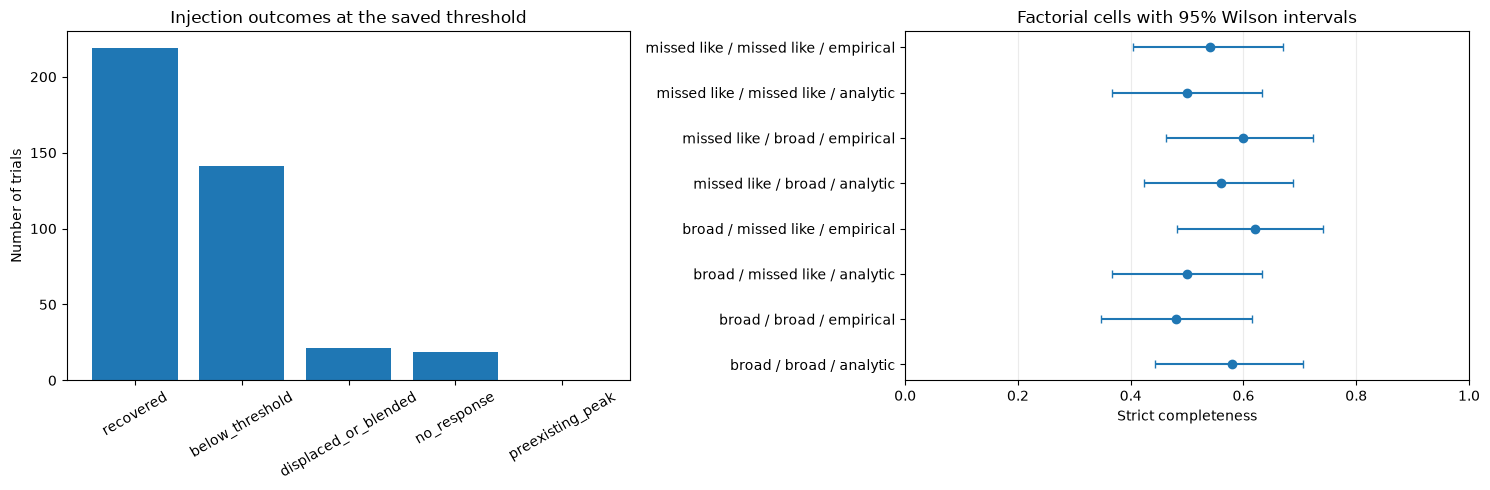

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

outcome_order = ["recovered", "below_threshold", "displaced_or_blended", "no_response", "preexisting_peak"]
outcome_counts = trials["outcome"].value_counts().reindex(outcome_order, fill_value=0)
axes[0].bar(outcome_counts.index, outcome_counts.values)
axes[0].set(title="Injection outcomes at the saved threshold", ylabel="Number of trials")
axes[0].tick_params(axis="x", rotation=30)

plot_table = primary_summary.copy()
plot_table["label"] = (
    plot_table["source_kind"].str.replace("_", " ")
    + " / "
    + plot_table["environment_kind"].str.replace("_", " ")
    + " / "
    + plot_table["renderer"]
)
y = np.arange(len(plot_table))
error = np.vstack((
    plot_table["completeness"] - plot_table["ci95_low"],
    plot_table["ci95_high"] - plot_table["completeness"],
))
axes[1].errorbar(plot_table["completeness"], y, xerr=error, fmt="o", capsize=3)
axes[1].set_yticks(y, plot_table["label"])
axes[1].set(xlim=(0, 1), xlabel="Strict completeness", title="Factorial cells with 95% Wilson intervals")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(cfg.output_dir / "outcomes_and_factorial_completeness.png", dpi=180, bbox_inches="tight")
plt.show()


## Selection-function plots

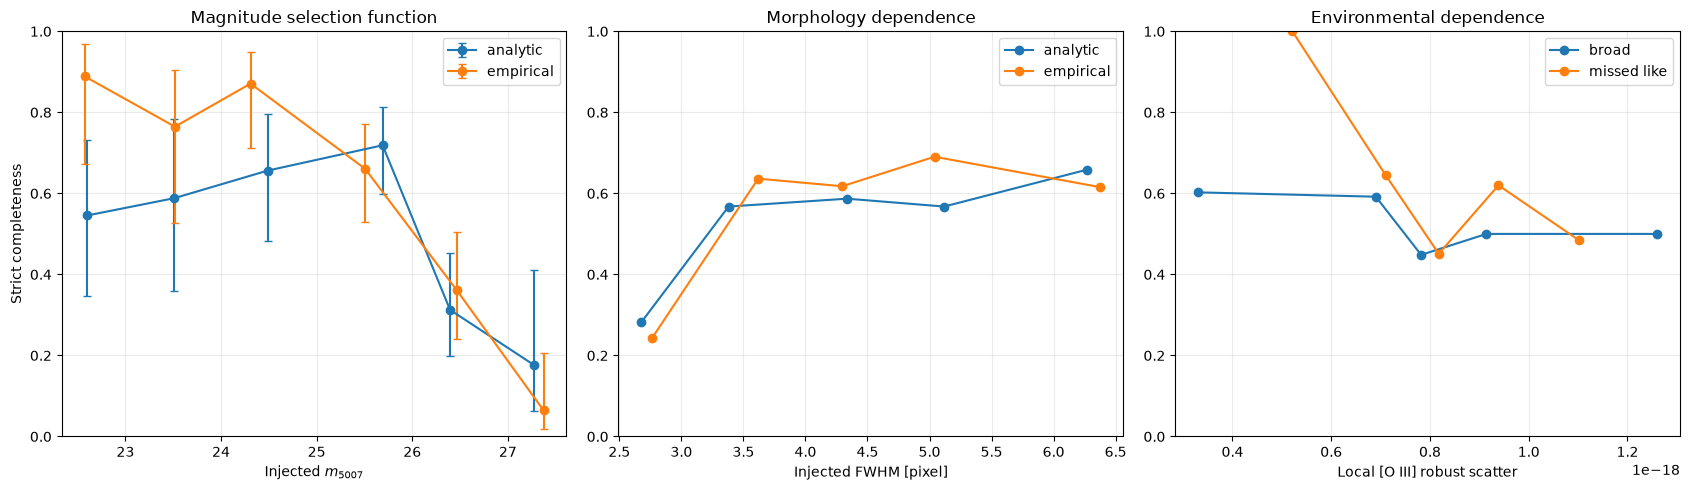

In [27]:
def binned_completeness(frame, column, bins):
    work = frame.copy()
    work["bin"] = pd.cut(work[column], bins=bins, include_lowest=True, duplicates="drop")
    rows = []
    for interval, group in work.groupby("bin", observed=True):
        successes = int(group["strict_recovery"].sum())
        total = len(group)
        low, high = wilson_interval(successes, total)
        rows.append({
            "x": group[column].median(),
            "N": total,
            "completeness": successes / total,
            "ci95_low": low,
            "ci95_high": high,
            "label": str(interval),
        })
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for renderer, group in trials.groupby("renderer"):
    curve = binned_completeness(group, "m5007", np.arange(22, 29, 1))
    axes[0].errorbar(
        curve["x"], curve["completeness"],
        yerr=[curve["completeness"] - curve["ci95_low"], curve["ci95_high"] - curve["completeness"]],
        marker="o", capsize=3, label=renderer,
    )
axes[0].set(xlabel=r"Injected $m_{5007}$", ylabel="Strict completeness", title="Magnitude selection function", ylim=(0, 1))
axes[0].legend()

fwhm_bins = np.unique(np.quantile(trials["fwhm_pix"], np.linspace(0, 1, 6)))
for renderer, group in trials.groupby("renderer"):
    curve = binned_completeness(group, "fwhm_pix", fwhm_bins)
    axes[1].plot(curve["x"], curve["completeness"], marker="o", label=renderer)
axes[1].set(xlabel="Injected FWHM [pixel]", title="Morphology dependence", ylim=(0, 1))
axes[1].legend()

if scatter_unique >= 10:
    scatter_bins = np.unique(np.quantile(trials["oiii_local_scatter"], np.linspace(0, 1, 6)))
    for environment, group in trials.groupby("environment_kind"):
        curve = binned_completeness(group, "oiii_local_scatter", scatter_bins)
        axes[2].plot(curve["x"], curve["completeness"], marker="o", label=environment.replace("_", " "))
    axes[2].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
    axes[2].legend()
else:
    axes[2].text(0.5, 0.5, "Rerun required after scatter-floor fix", ha="center", va="center")
axes[2].set(xlabel="Local [O III] robust scatter", title="Environmental dependence", ylim=(0, 1))

for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(cfg.output_dir / "injection_selection_functions.png", dpi=180, bbox_inches="tight")
plt.show()


## Completeness at a fixed unmatched-candidate budget

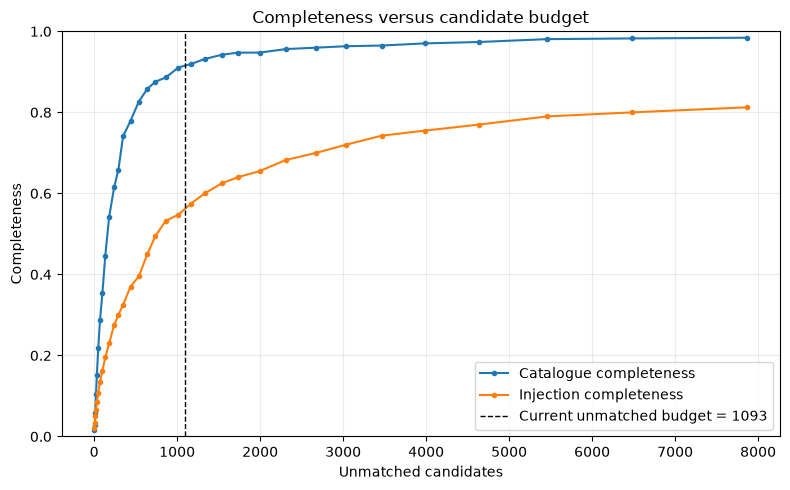

,threshold,catalogue_completeness,unmatched_candidates,total_candidates,injection_completeness
13,0.425,0.919440,1167,1692,0.5750
14,0.450,0.910683,1014,1534,0.5475
15,0.475,0.886165,863,1369,0.5325
12,0.400,0.931699,1332,1864,0.6000
16,0.500,0.875657,738,1238,0.4950


In [28]:
def greedy_catalogue_match_count(catalogue_xy, detections, tolerance):
    if len(detections) == 0:
        return 0, 0
    tree = cKDTree(detections[:, :2])
    pairs = []
    for catalog_index, position in enumerate(catalogue_xy):
        for detection_index in tree.query_ball_point(position, tolerance):
            distance = float(np.hypot(*(detections[detection_index, :2] - position)))
            pairs.append((distance, catalog_index, detection_index))
    used_catalogue = set()
    used_detections = set()
    for _, catalog_index, detection_index in sorted(pairs):
        if catalog_index not in used_catalogue and detection_index not in used_detections:
            used_catalogue.add(catalog_index)
            used_detections.add(detection_index)
    matched = len(used_catalogue)
    return matched, len(detections) - len(used_detections)

threshold_rows = []
catalogue_xy = catalogue_positions(real_catalogue)
has_sweep_scores = {"baseline_match_peak_score", "injected_match_peak_score"}.issubset(trials.columns)

for candidate_threshold in np.linspace(0.10, 0.90, 33):
    detections = find_peaks(baseline_heatmap, candidate_threshold, cfg.min_distance)
    matched, unmatched = greedy_catalogue_match_count(catalogue_xy, detections, cfg.match_radius)
    row = {
        "threshold": candidate_threshold,
        "catalogue_completeness": matched / len(catalogue_xy),
        "unmatched_candidates": unmatched,
        "total_candidates": len(detections),
    }
    if has_sweep_scores:
        baseline_score = trials["baseline_match_peak_score"].fillna(-np.inf)
        injected_score = trials["injected_match_peak_score"].fillna(-np.inf)
        row["injection_completeness"] = np.mean(
            (baseline_score < candidate_threshold) & (injected_score >= candidate_threshold)
        )
    threshold_rows.append(row)

threshold_curve = pd.DataFrame(threshold_rows)
threshold_curve.to_csv(cfg.output_dir / "threshold_candidate_budget_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    threshold_curve["unmatched_candidates"],
    threshold_curve["catalogue_completeness"],
    marker="o", ms=3, label="Catalogue completeness",
)
if has_sweep_scores:
    ax.plot(
        threshold_curve["unmatched_candidates"],
        threshold_curve["injection_completeness"],
        marker="o", ms=3, label="Injection completeness",
    )
else:
    print("Rerun injections once to add threshold-independent injected-peak scores.")
ax.axvline(1093, linestyle="--", color="black", linewidth=1, label="Current unmatched budget = 1093")
ax.set(
    xlabel="Unmatched candidates",
    ylabel="Completeness",
    ylim=(0, 1),
    title="Completeness versus candidate budget",
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(cfg.output_dir / "completeness_vs_candidate_budget.png", dpi=180, bbox_inches="tight")
plt.show()

display(threshold_curve.iloc[(threshold_curve["unmatched_candidates"] - 1093).abs().argsort()[:5]])


## Interpretation

`pilot_injection_recovery.csv` contains one row per trial. Only `outcome == "recovered"` counts toward strict completeness. Treat the 400-injection development run as a pilot; do not tune using the final test partition.